In [1]:
import sys
print(sys.executable)

c:\Users\kookie\AppData\Local\Python\pythoncore-3.14-64\python.exe


In [1]:
import sys
print(sys.executable)

c:\Users\kookie\OneDrive\MMA3001_project\.venv\Scripts\python.exe


# Week 2 — Clean, segment and explore the elephant trajectories

Run the cells in order. Stop at D1, D2 and D3 and record each decision before continuing.


In [2]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, display


current_folder = Path.cwd().resolve()

if (current_folder / "data" / "raw").exists():
    PROJECT_ROOT = current_folder
elif (current_folder.parent / "data" / "raw").exists():
    PROJECT_ROOT = current_folder.parent
else:
    raise FileNotFoundError(
        "Cannot find data/raw. Open the complete MMA3001_project folder."
    )


SRC_FOLDER = PROJECT_ROOT / "src"

if str(SRC_FOLDER) not in sys.path:
    sys.path.insert(0, str(SRC_FOLDER))


from preprocessing import (
    EXPECTED_ANIMALS,
    EXPECTED_CLEAN_ROWS,
    EXPECTED_RAW_LONG_GAPS,
    EXPECTED_RAW_ROWS,
    EXPECTED_REMOVED_SPIKES,
    EXPECTED_SEGMENTS,
    GAP_THRESHOLD_MINUTES,
    add_movement_metrics,
    create_eda_figures,
    export_outputs,
    find_workbook,
    load_and_standardise,
    make_summary_tables,
    plot_candidate_spikes,
    remove_approved_spikes,
    screen_spike_candidates,
    segment_trajectories,
    validate_final_outputs,
)


RAW_FOLDER = PROJECT_ROOT / "data" / "raw"
PROCESSED_FOLDER = PROJECT_ROOT / "data" / "processed"
FIGURES_FOLDER = PROJECT_ROOT / "figures"
REPORTS_FOLDER = PROJECT_ROOT / "reports"
PRIVATE_FIGURES_FOLDER = PROJECT_ROOT / "private_figures"


for folder in [
    PROCESSED_FOLDER,
    FIGURES_FOLDER,
    REPORTS_FOLDER,
    PRIVATE_FIGURES_FOLDER,
]:
    folder.mkdir(parents=True, exist_ok=True)


print("Project root:", PROJECT_ROOT)

Project root: C:\Users\kookie\OneDrive\MMA3001_project


In [3]:
WORKBOOK = find_workbook(RAW_FOLDER)

standardised, audit = load_and_standardise(WORKBOOK)

display(
    pd.Series(
        audit,
        name="Observed value"
    ).to_frame()
)


assert audit["source_rows"] == EXPECTED_RAW_ROWS
assert audit["animal_count"] == EXPECTED_ANIMALS
assert (
    audit["raw_gaps_above_30_minutes"]
    == EXPECTED_RAW_LONG_GAPS
)

print("Standardisation checks passed.")

,Observed value
source_rows,60000.0
standardised_rows,60000.0
animal_count,6.0
required_missing_values,0.0
invalid_latitudes,0.0
invalid_longitudes,0.0
source_year_mismatches,0.0
source_day_of_year_mismatches,0.0
duplicate_rows,0.0
duplicate_events_consolidated,0.0


Standardisation checks passed.


C:\Users\kookie\AppData\Local\Temp\ipykernel_6728\3315865050.py:20: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  candidates[candidate_columns].round(3)


,AnimalID,Timestamp,IncomingInterval_min,OutgoingInterval_min,IncomingDistance_m,OutgoingDistance_m,NeighbourBridgeDistance_m,IncomingSpeed_mps,OutgoingSpeed_mps
0,LOAF-18-f-2981-1,2019-06-13 09:00:00,14.0,15.0,6022.694,6279.743,461.120,7.170,6.977
1,LOAF-18-f-2981-1,2019-06-13 11:00:00,15.0,15.0,4819.846,4909.648,5462.433,5.355,5.455
2,LOAF-18-f-2981-1,2019-06-13 11:15:00,15.0,15.0,4909.648,5708.943,4794.372,5.455,6.343
3,LOAF-18-f-2981-1,2019-08-29 23:30:00,15.0,15.0,6549.986,6607.448,61.861,7.278,7.342
4,LOAF-18-f-2982-1,2019-07-19 17:45:00,15.0,15.0,6329.871,6232.801,145.462,7.033,6.925
5,LOAF-18-f-2986-1,2019-07-30 14:00:00,15.0,15.0,12648.654,12771.685,168.600,14.054,14.191


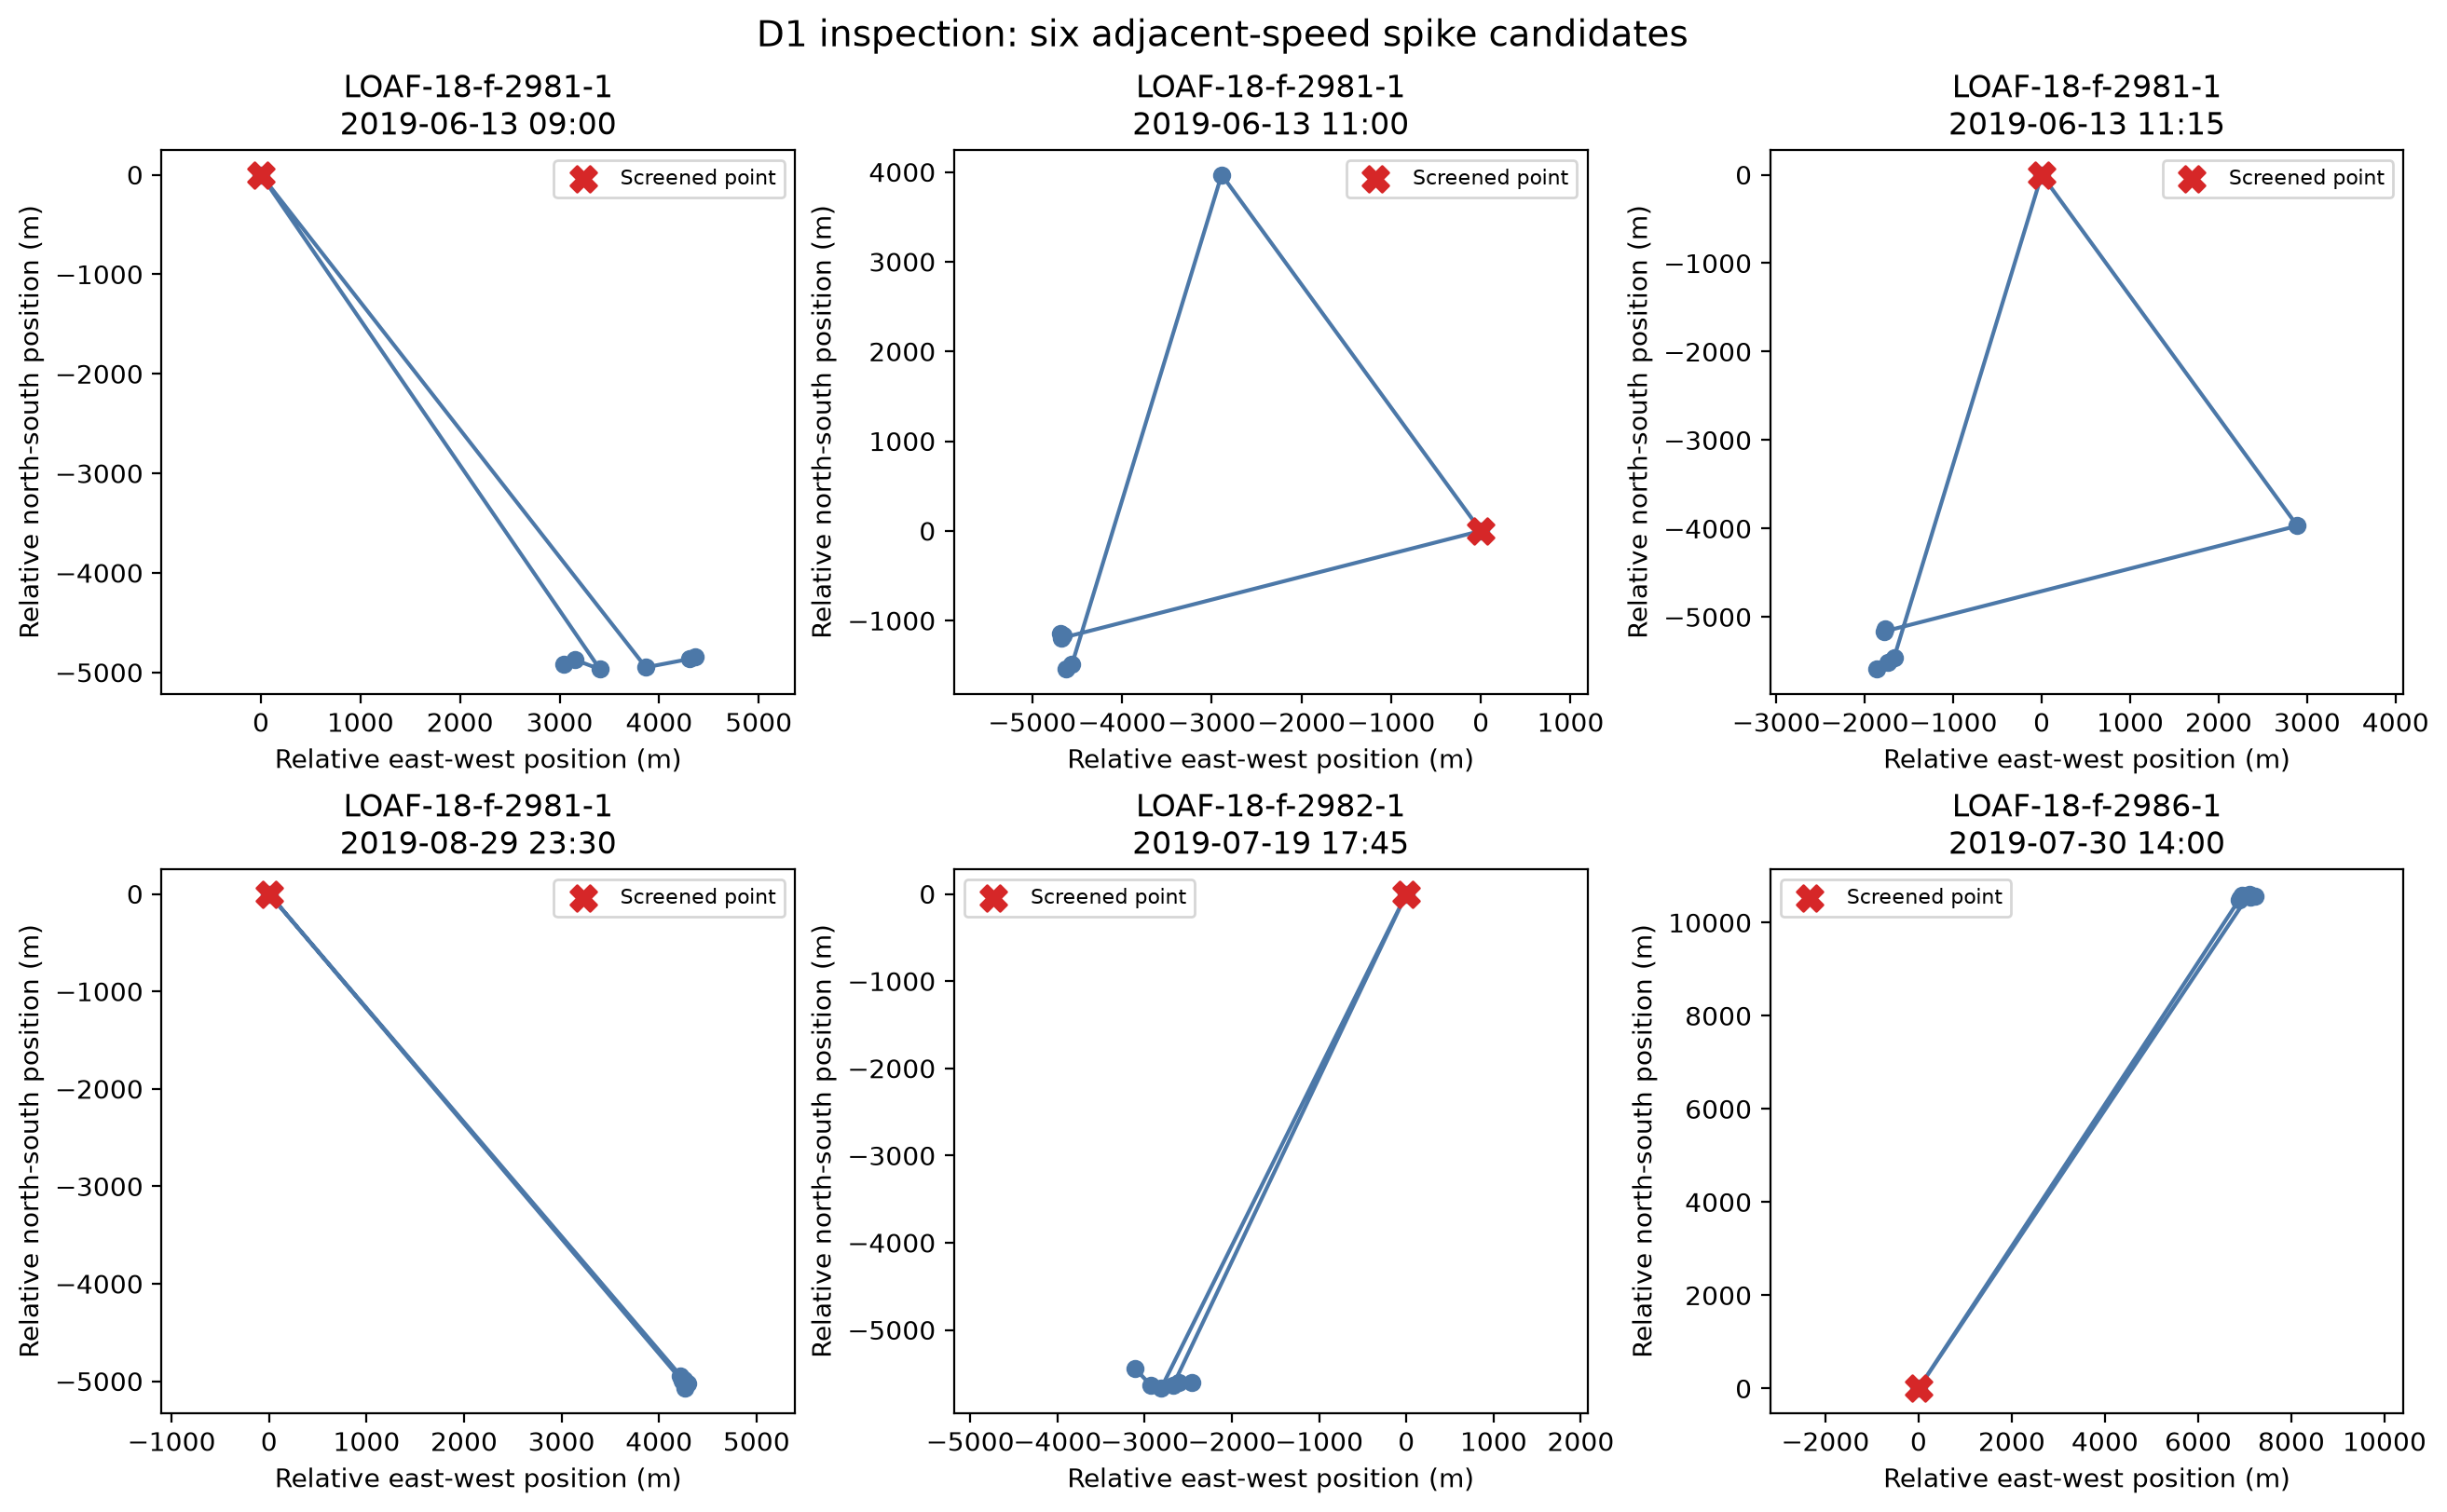

In [4]:
candidates = screen_spike_candidates(
    standardised
)


candidate_columns = [
    "AnimalID",
    "Timestamp",
    "IncomingInterval_min",
    "OutgoingInterval_min",
    "IncomingDistance_m",
    "OutgoingDistance_m",
    "NeighbourBridgeDistance_m",
    "IncomingSpeed_mps",
    "OutgoingSpeed_mps",
]


display(
    candidates[candidate_columns].round(3)
)


assert len(candidates) == EXPECTED_REMOVED_SPIKES


candidate_report = (
    REPORTS_FOLDER
    / "week2_spike_candidates.csv"
)

candidates[
    candidate_columns + ["ScreenRule"]
].to_csv(
    candidate_report,
    index=False,
)


candidate_figure = (
    PRIVATE_FIGURES_FOLDER
    / "week2_candidate_spike_inspection.png"
)


plot_candidate_spikes(
    standardised,
    candidates,
    candidate_figure,
)


display(
    Image(
        filename=str(candidate_figure),
        width=1000
    )
)

In [5]:
cleaned, removed = remove_approved_spikes(
    standardised,
    candidates,
)


print(
    "Rows before removal:",
    len(standardised)
)

print(
    "Rows removed:",
    len(removed)
)

print(
    "Rows retained:",
    len(cleaned)
)


display(
    removed[
        [
            "AnimalID",
            "Timestamp",
            "IncomingSpeed_mps",
            "OutgoingSpeed_mps",
            "RemovalReason",
        ]
    ]
)

Rows before removal: 60000
Rows removed: 6
Rows retained: 59994


,AnimalID,Timestamp,IncomingSpeed_mps,OutgoingSpeed_mps,RemovalReason
0,LOAF-18-f-2981-1,2019-06-13 09:00:00,7.169874,6.977492,Approved at D1: both adjacent speeds exceeded ...
1,LOAF-18-f-2981-1,2019-06-13 11:00:00,5.355384,5.455164,Approved at D1: both adjacent speeds exceeded ...
2,LOAF-18-f-2981-1,2019-06-13 11:15:00,5.455164,6.343270,Approved at D1: both adjacent speeds exceeded ...
3,LOAF-18-f-2981-1,2019-08-29 23:30:00,7.277763,7.341609,Approved at D1: both adjacent speeds exceeded ...
4,LOAF-18-f-2982-1,2019-07-19 17:45:00,7.033190,6.925334,Approved at D1: both adjacent speeds exceeded ...
5,LOAF-18-f-2986-1,2019-07-30 14:00:00,14.054060,14.190761,Approved at D1: both adjacent speeds exceeded ...


In [6]:
cleaned = segment_trajectories(
    cleaned
)


long_gap_count = int(
    cleaned["GapFromPrevious_min"]
    .gt(GAP_THRESHOLD_MINUTES)
    .sum()
)


segment_count = int(
    cleaned["SegmentID"].nunique()
)


print(
    "Post-cleaning gaps above 30 minutes:",
    long_gap_count
)

print(
    "Continuous segments:",
    segment_count
)


display(
    cleaned.loc[
        cleaned["SegmentStart"],
        [
            "AnimalID",
            "Timestamp",
            "GapFromPrevious_min",
            "SegmentID",
        ],
    ].head(15)
)


assert long_gap_count == 71
assert segment_count == EXPECTED_SEGMENTS

Post-cleaning gaps above 30 minutes: 71
Continuous segments: 77


,AnimalID,Timestamp,GapFromPrevious_min,SegmentID
0,LOAF-18-f-2981-1,2019-05-18 11:46:00,NaN,LOAF-18-f-2981-1_S001
185,LOAF-18-f-2981-1,2019-05-20 10:46:00,31.0,LOAF-18-f-2981-1_S002
2460,LOAF-18-f-2981-1,2019-06-13 11:30:00,45.0,LOAF-18-f-2981-1_S003
4346,LOAF-18-f-2981-1,2019-07-03 09:01:00,31.0,LOAF-18-f-2981-1_S004
5079,LOAF-18-f-2981-1,2019-07-11 02:31:00,31.0,LOAF-18-f-2981-1_S005
5808,LOAF-18-f-2981-1,2019-07-18 19:31:00,31.0,LOAF-18-f-2981-1_S006
6205,LOAF-18-f-2981-1,2019-07-23 00:16:00,31.0,LOAF-18-f-2981-1_S007
7724,LOAF-18-f-2981-1,2019-08-08 00:16:00,31.0,LOAF-18-f-2981-1_S008
7819,LOAF-18-f-2981-1,2019-08-09 00:16:00,31.0,LOAF-18-f-2981-1_S009
8010,LOAF-18-f-2981-1,2019-08-11 00:31:00,46.0,LOAF-18-f-2981-1_S010


In [7]:
cleaned = add_movement_metrics(
    cleaned
)


validation = validate_final_outputs(
    cleaned,
    removed,
)


display(
    pd.Series(
        validation,
        name="Observed value"
    ).to_frame()
)


(
    animal_summary,
    segment_summary,
    daily_summary,
    projection_summary,
) = make_summary_tables(
    cleaned
)


display(
    projection_summary
)


display(
    animal_summary.round(3)
)

,Observed value
cleaned_rows,59994
removed_spikes,6
animal_count,6
clean_long_gaps_above_30_minutes,71
segment_count,77
duplicate_animal_timestamp_events,0
missing_required_values,0
movement_values_across_segment_boundaries,0
maximum_speed_mps_after_cleaning,2.565837
status,PASS


,Metric,Value
0,median_absolute_difference_m,0.004309
1,p95_absolute_difference_m,0.119265
2,maximum_absolute_difference_m,2.901643
3,median_percentage_difference,0.007735
4,p95_percentage_difference,0.105517
5,maximum_percentage_difference,0.218461


C:\Users\kookie\AppData\Local\Temp\ipykernel_6728\1373598640.py:36: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  animal_summary.round(3)


,AnimalID,CleanedFixes,Start,End,SegmentCount,MedianGap_min,MaxGap_min,MedianSpeed_mps,P95Speed_mps,TotalObservedDistance_km
0,LOAF-18-f-2981-1,9996,2019-05-18 11:46:00,2019-08-31 23:00:00,11,15.0,46.0,0.064,0.337,947.229
1,LOAF-18-f-2982-1,9999,2019-05-03 02:18:00,2019-08-16 10:15:00,8,15.0,46.0,0.075,0.378,1066.901
2,LOAF-18-f-2983-1,10000,2019-08-22 00:30:00,2019-12-06 01:00:00,24,15.0,91.0,0.092,0.503,1377.316
3,LOAF-18-f-2984-1,10000,2018-08-17 01:16:00,2018-11-30 23:00:00,23,15.0,46.0,0.086,0.423,1208.452
4,LOAF-18-f-2985-1,10000,2019-08-07 03:16:00,2019-11-20 11:15:00,4,15.0,45.0,0.100,0.523,1445.547
5,LOAF-18-f-2986-1,9999,2019-05-30 11:01:00,2019-09-12 23:45:00,7,15.0,45.0,0.075,0.419,1158.315


In [8]:
data_paths = export_outputs(
    cleaned,
    removed,
    candidates,
    audit,
    validation,
    animal_summary,
    segment_summary,
    daily_summary,
    projection_summary,
    PROCESSED_FOLDER,
    REPORTS_FOLDER,
)


figure_paths = create_eda_figures(
    cleaned,
    daily_summary,
    FIGURES_FOLDER,
)


print("Saved data and report files:")

for path in data_paths:
    print(
        " -",
        path.relative_to(PROJECT_ROOT)
    )


print("Saved figures:")

for path in figure_paths:
    print(
        " -",
        path.relative_to(PROJECT_ROOT)
    )

Saved data and report files:
 - data\processed\elephant_gps_cleaned_reference.csv
 - data\processed\removed_spatial_spikes.csv
 - reports\week2_spike_candidates.csv
 - reports\week2_animal_summary.csv
 - reports\week2_segment_summary.csv
 - reports\week2_daily_summary.csv
 - reports\week2_projection_comparison.csv
 - reports\week2_preprocessing_summary.json
Saved figures:
 - figures\week2_01_relative_paths.png
 - figures\week2_02_recording_coverage.png
 - figures\week2_03_time_gap_distribution.png
 - figures\week2_04_speed_distribution.png
 - figures\week2_05_complete_day_distance.png


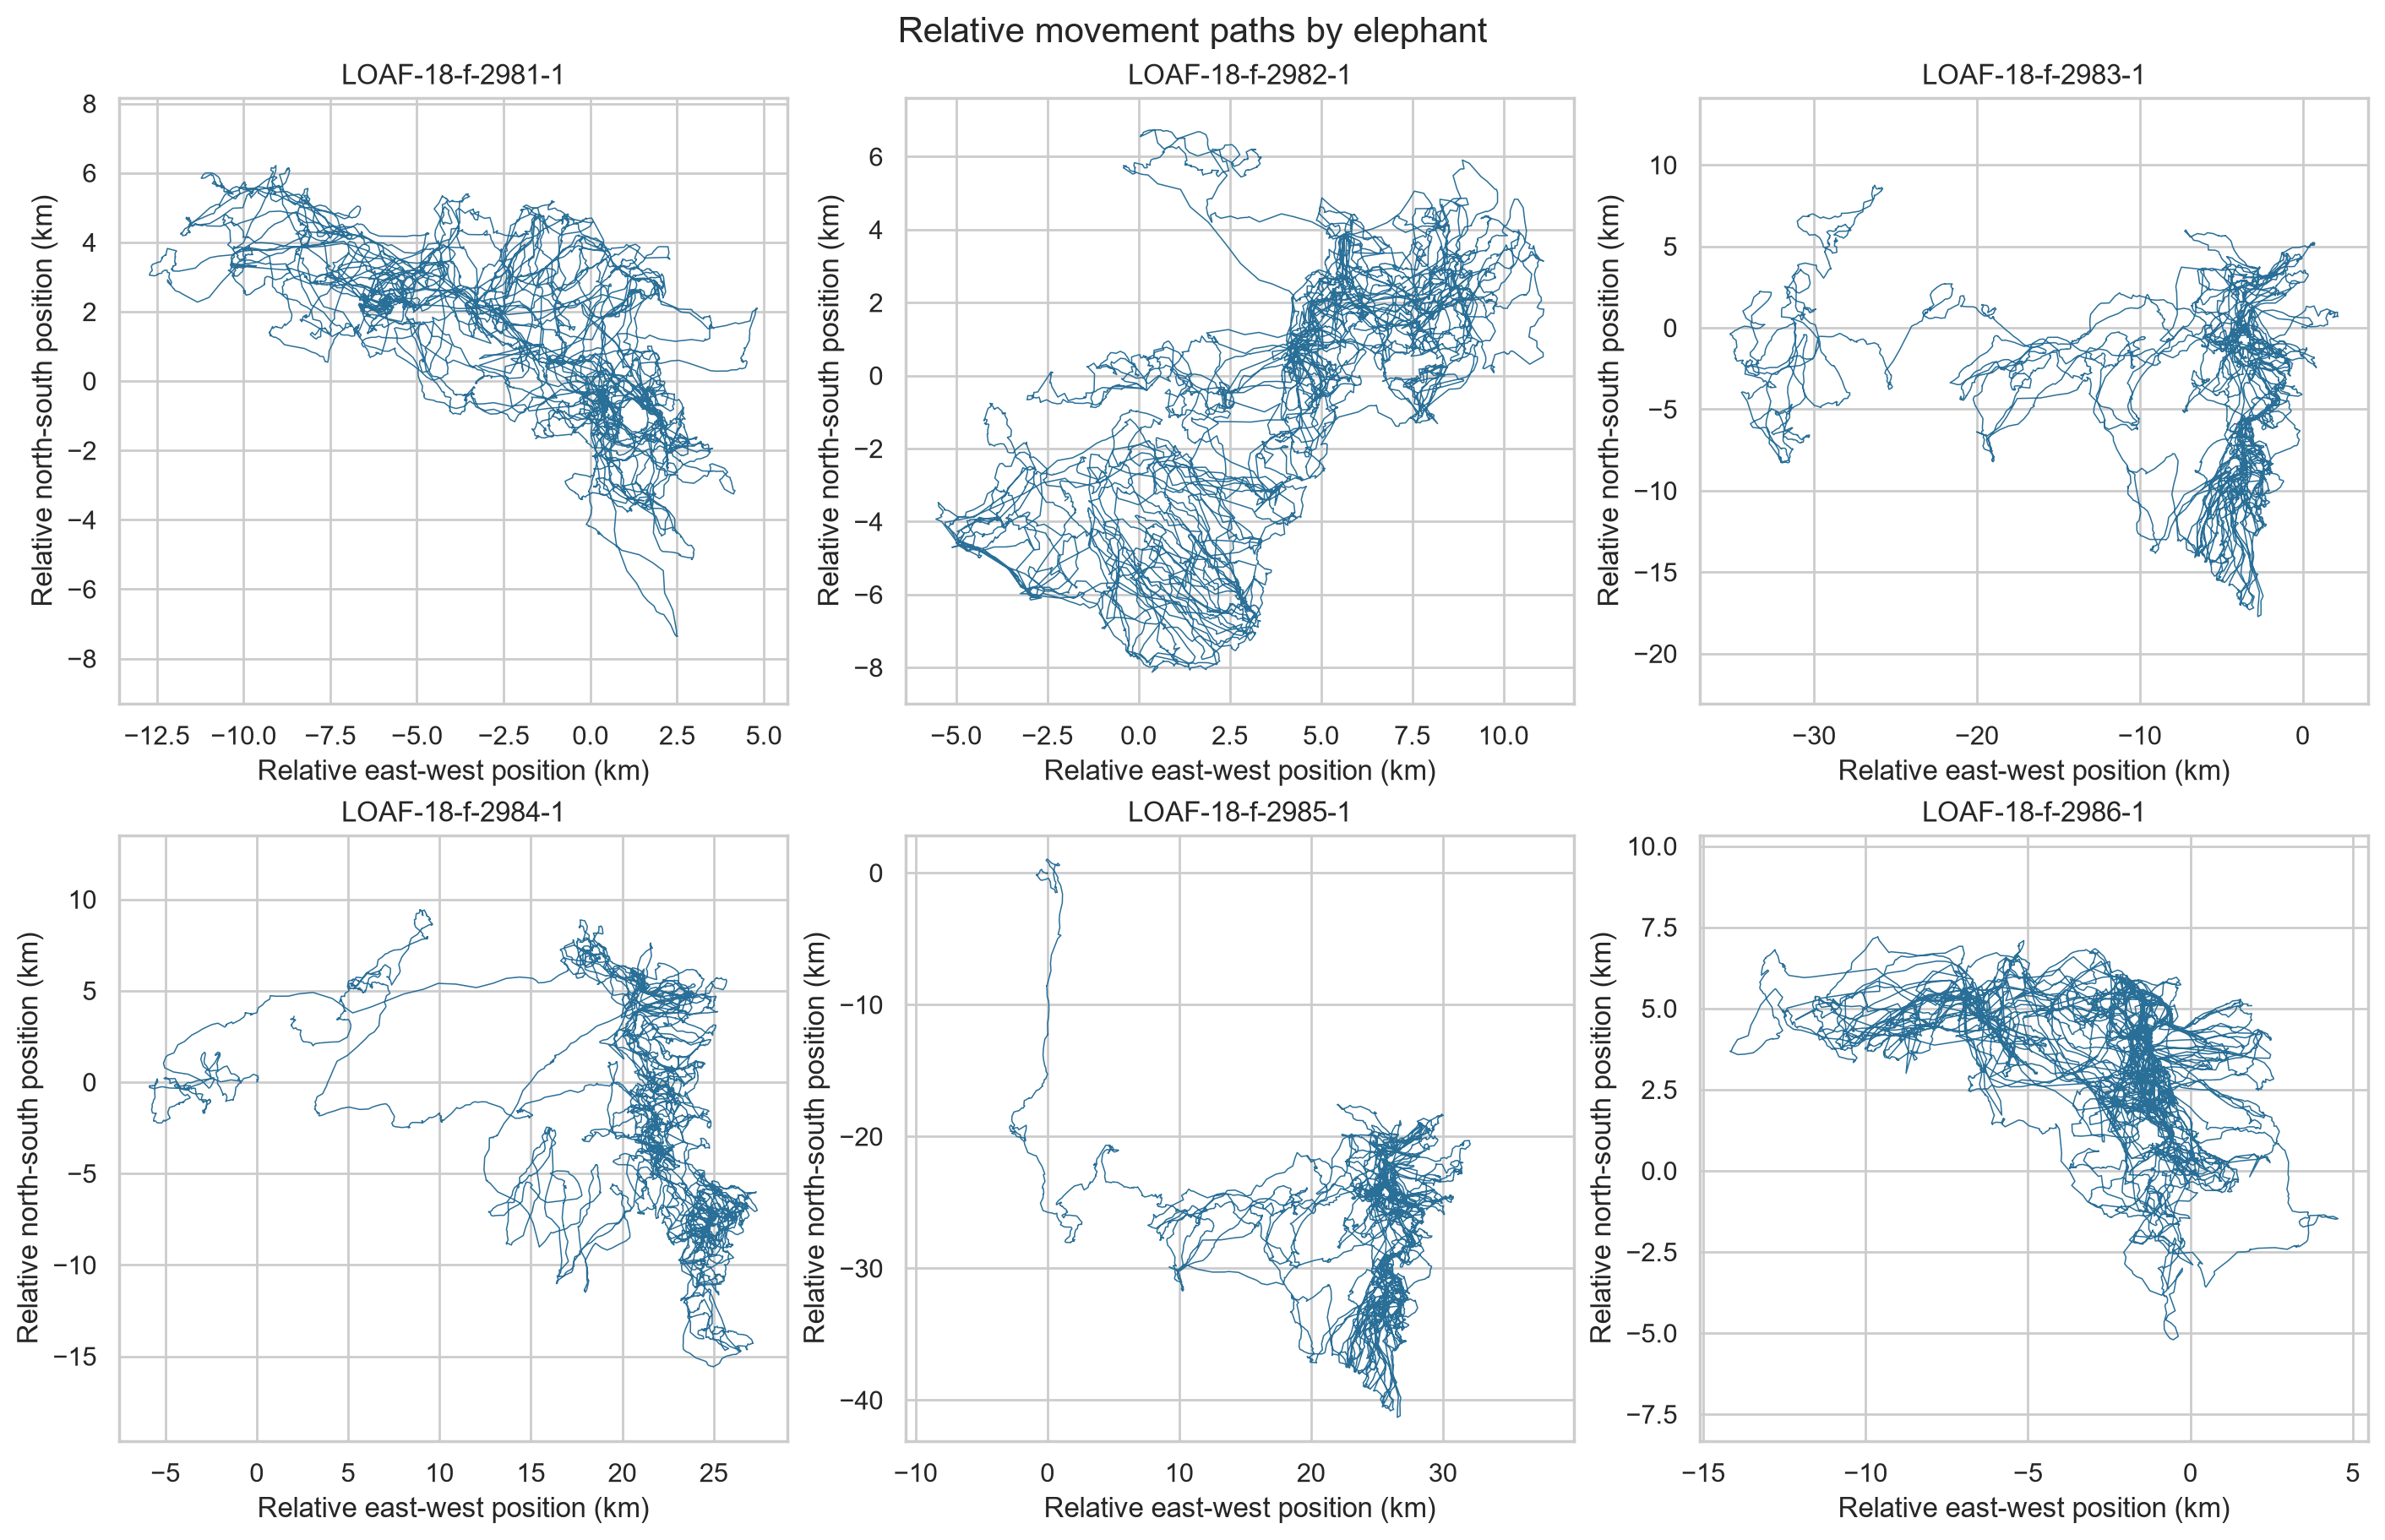

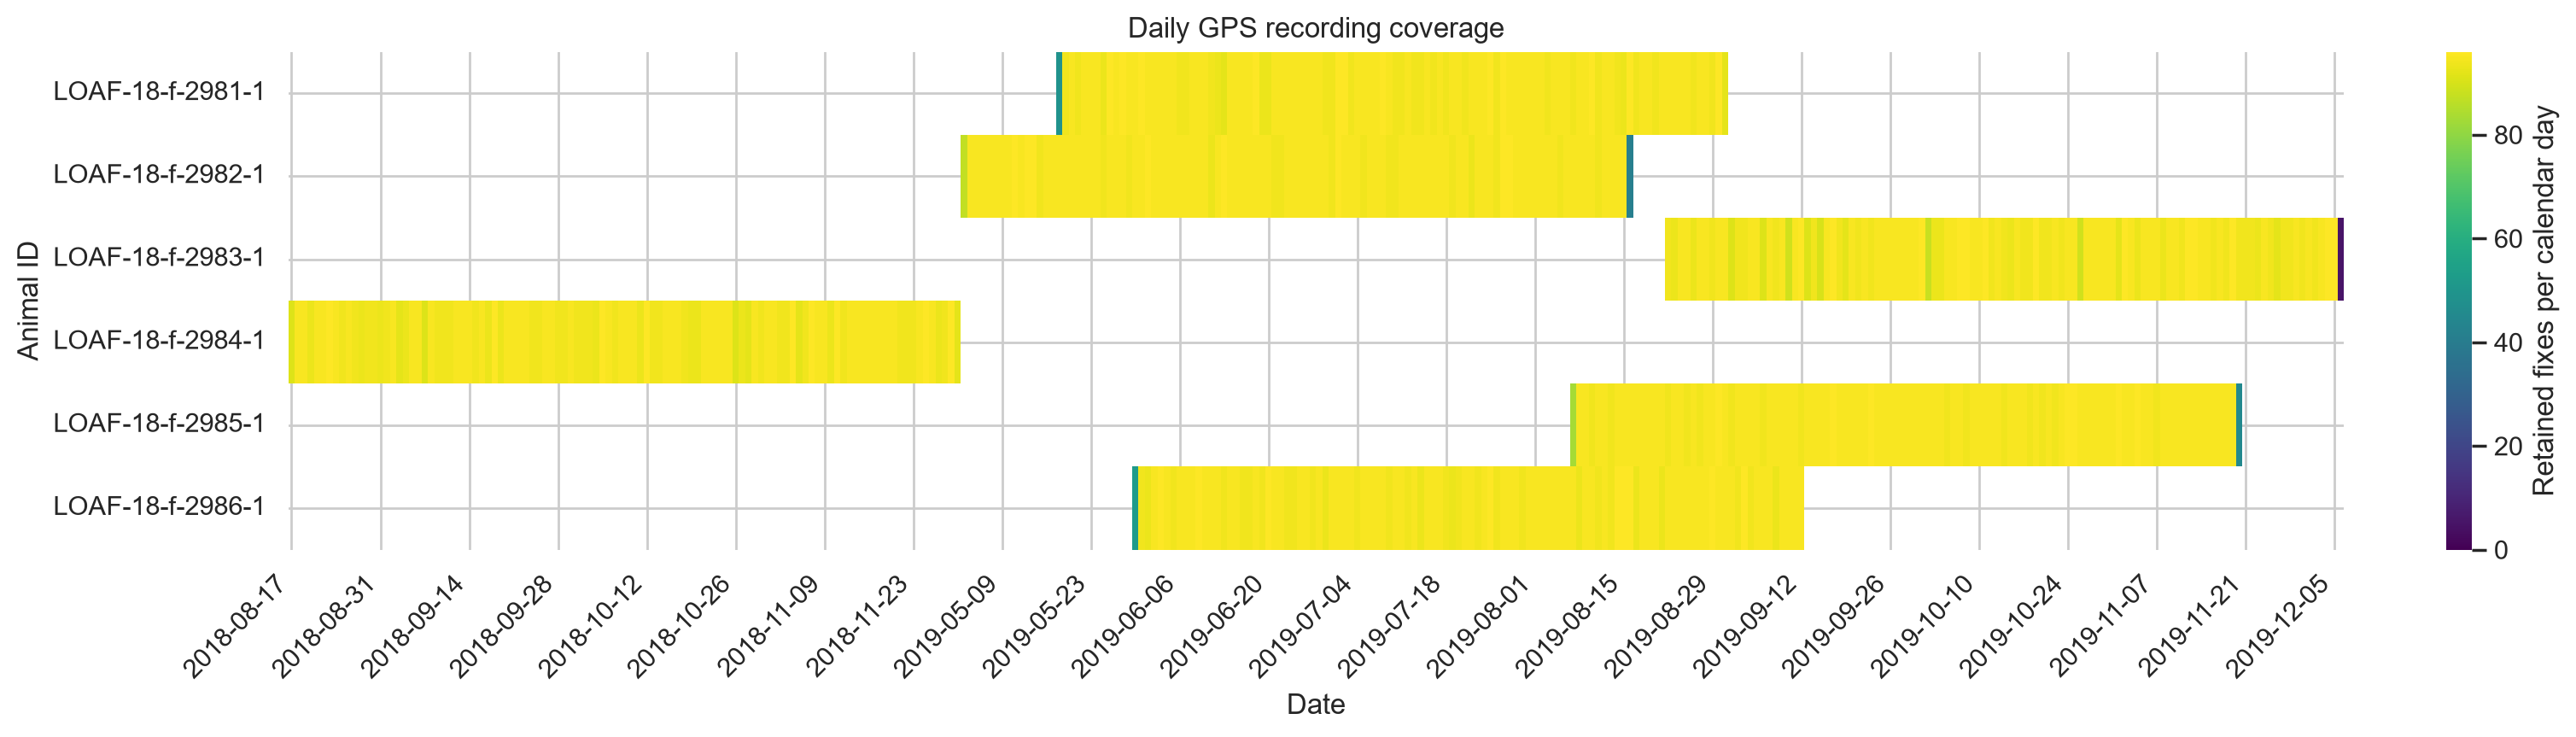

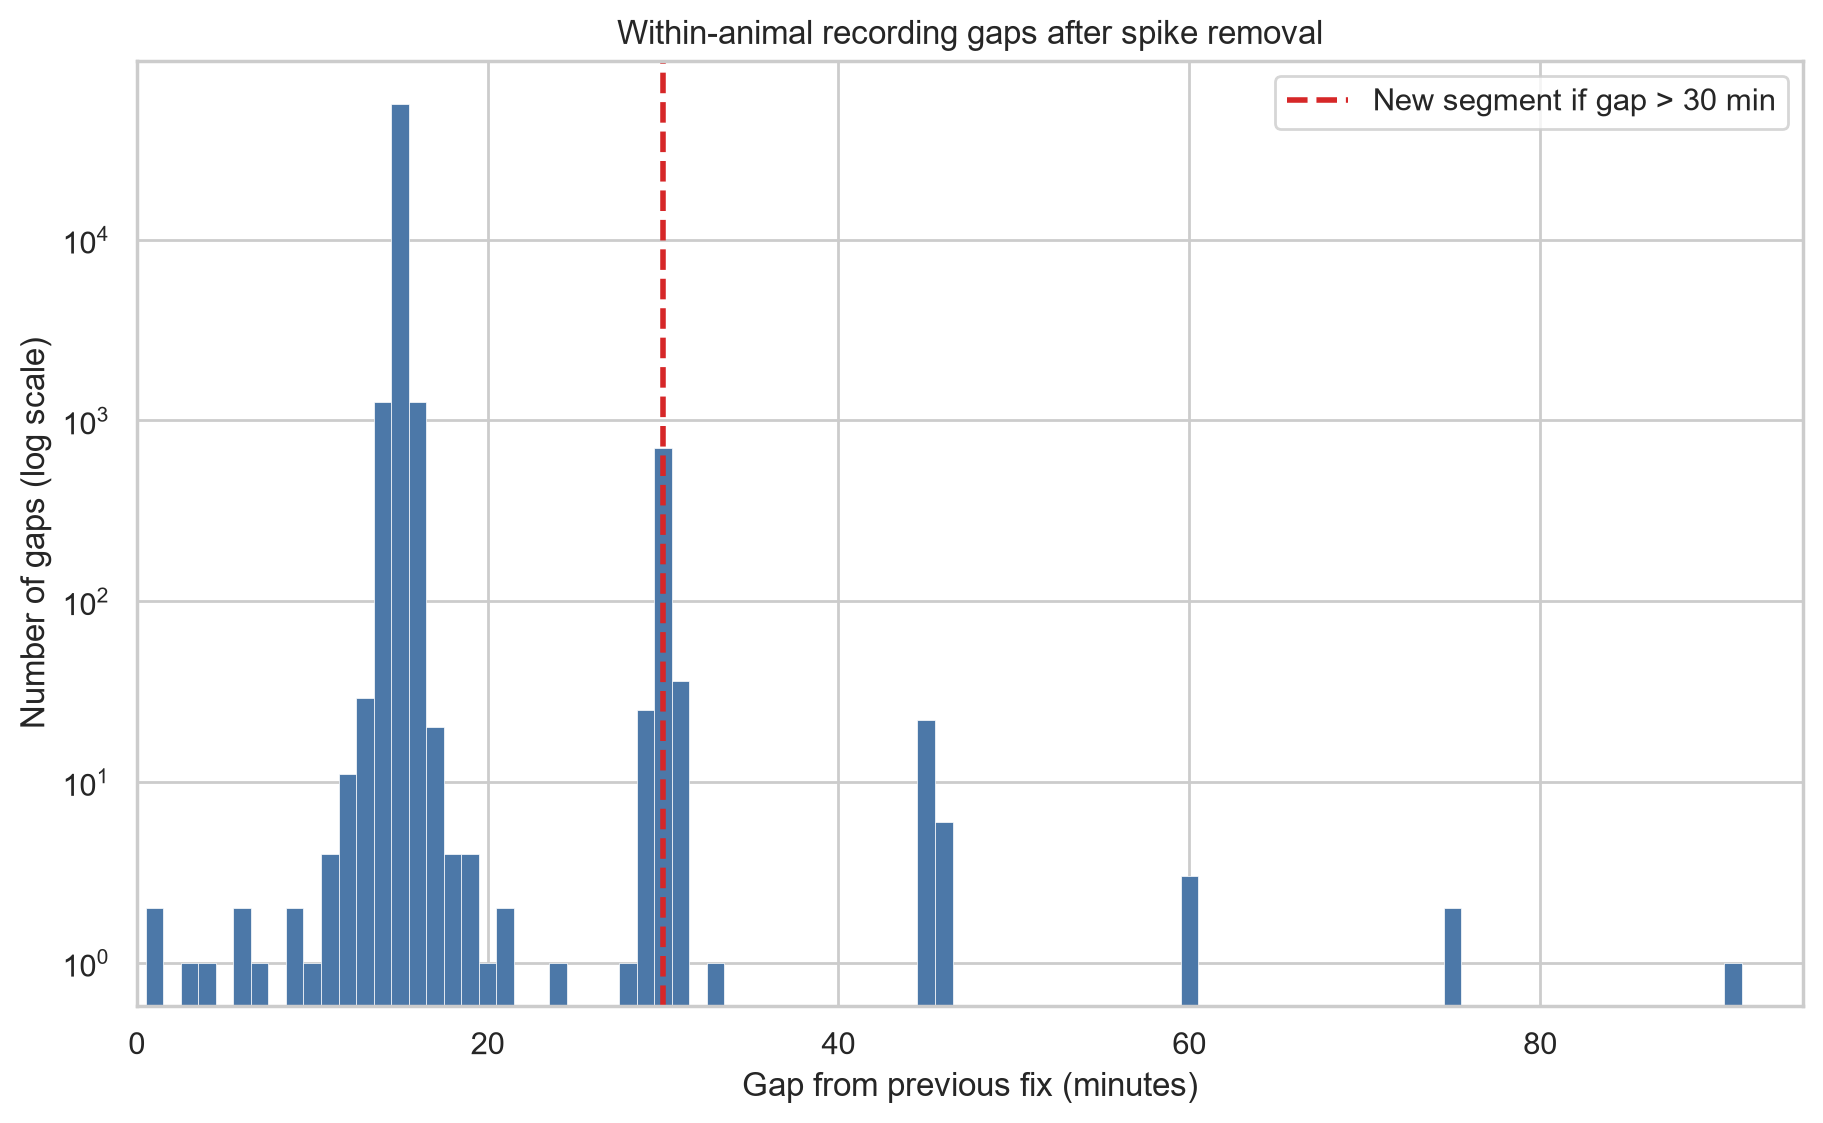

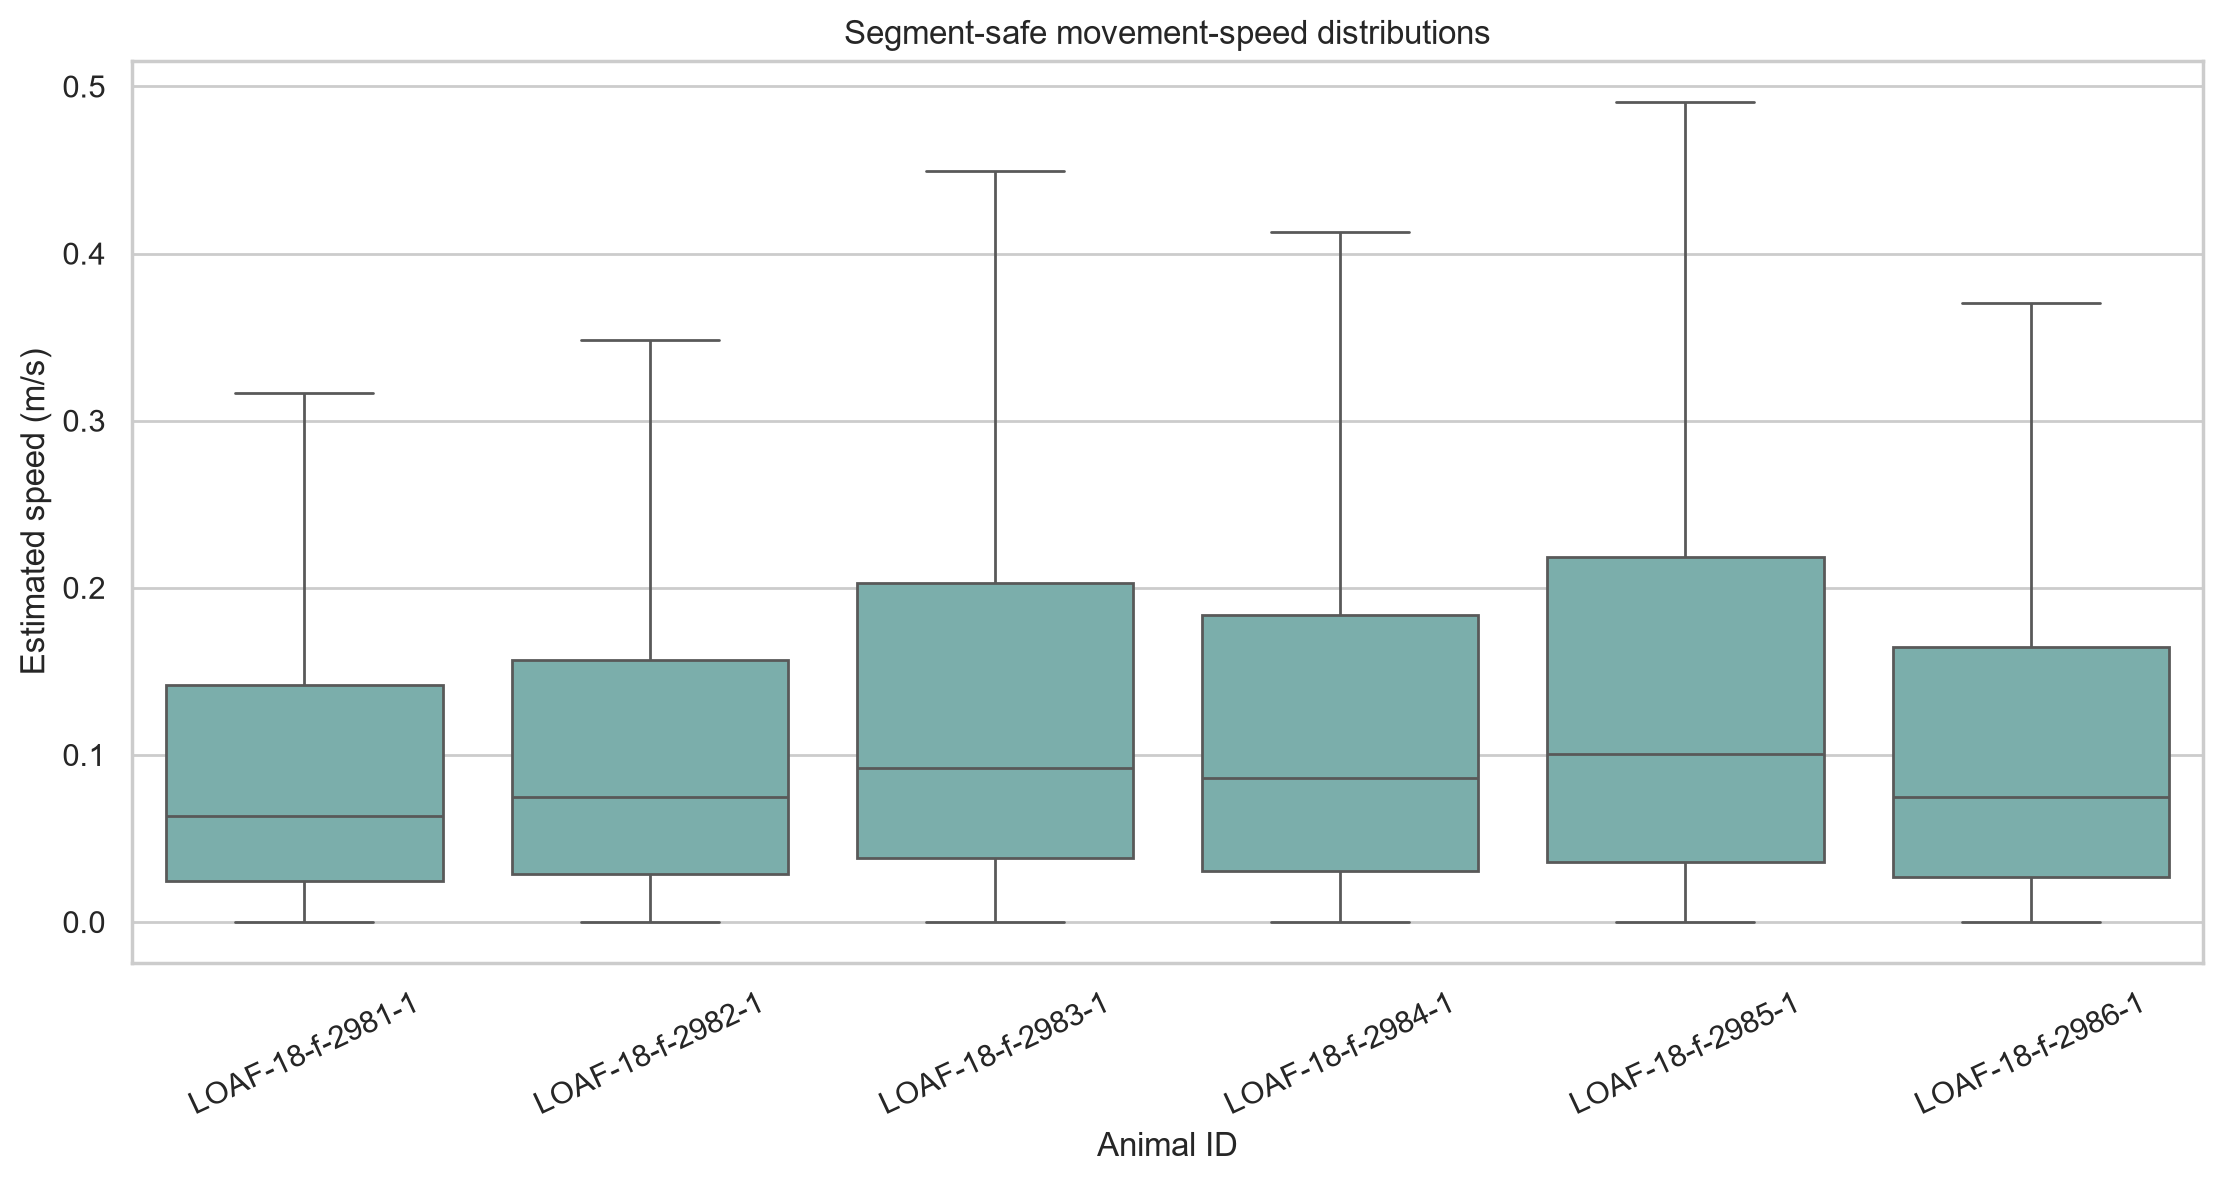

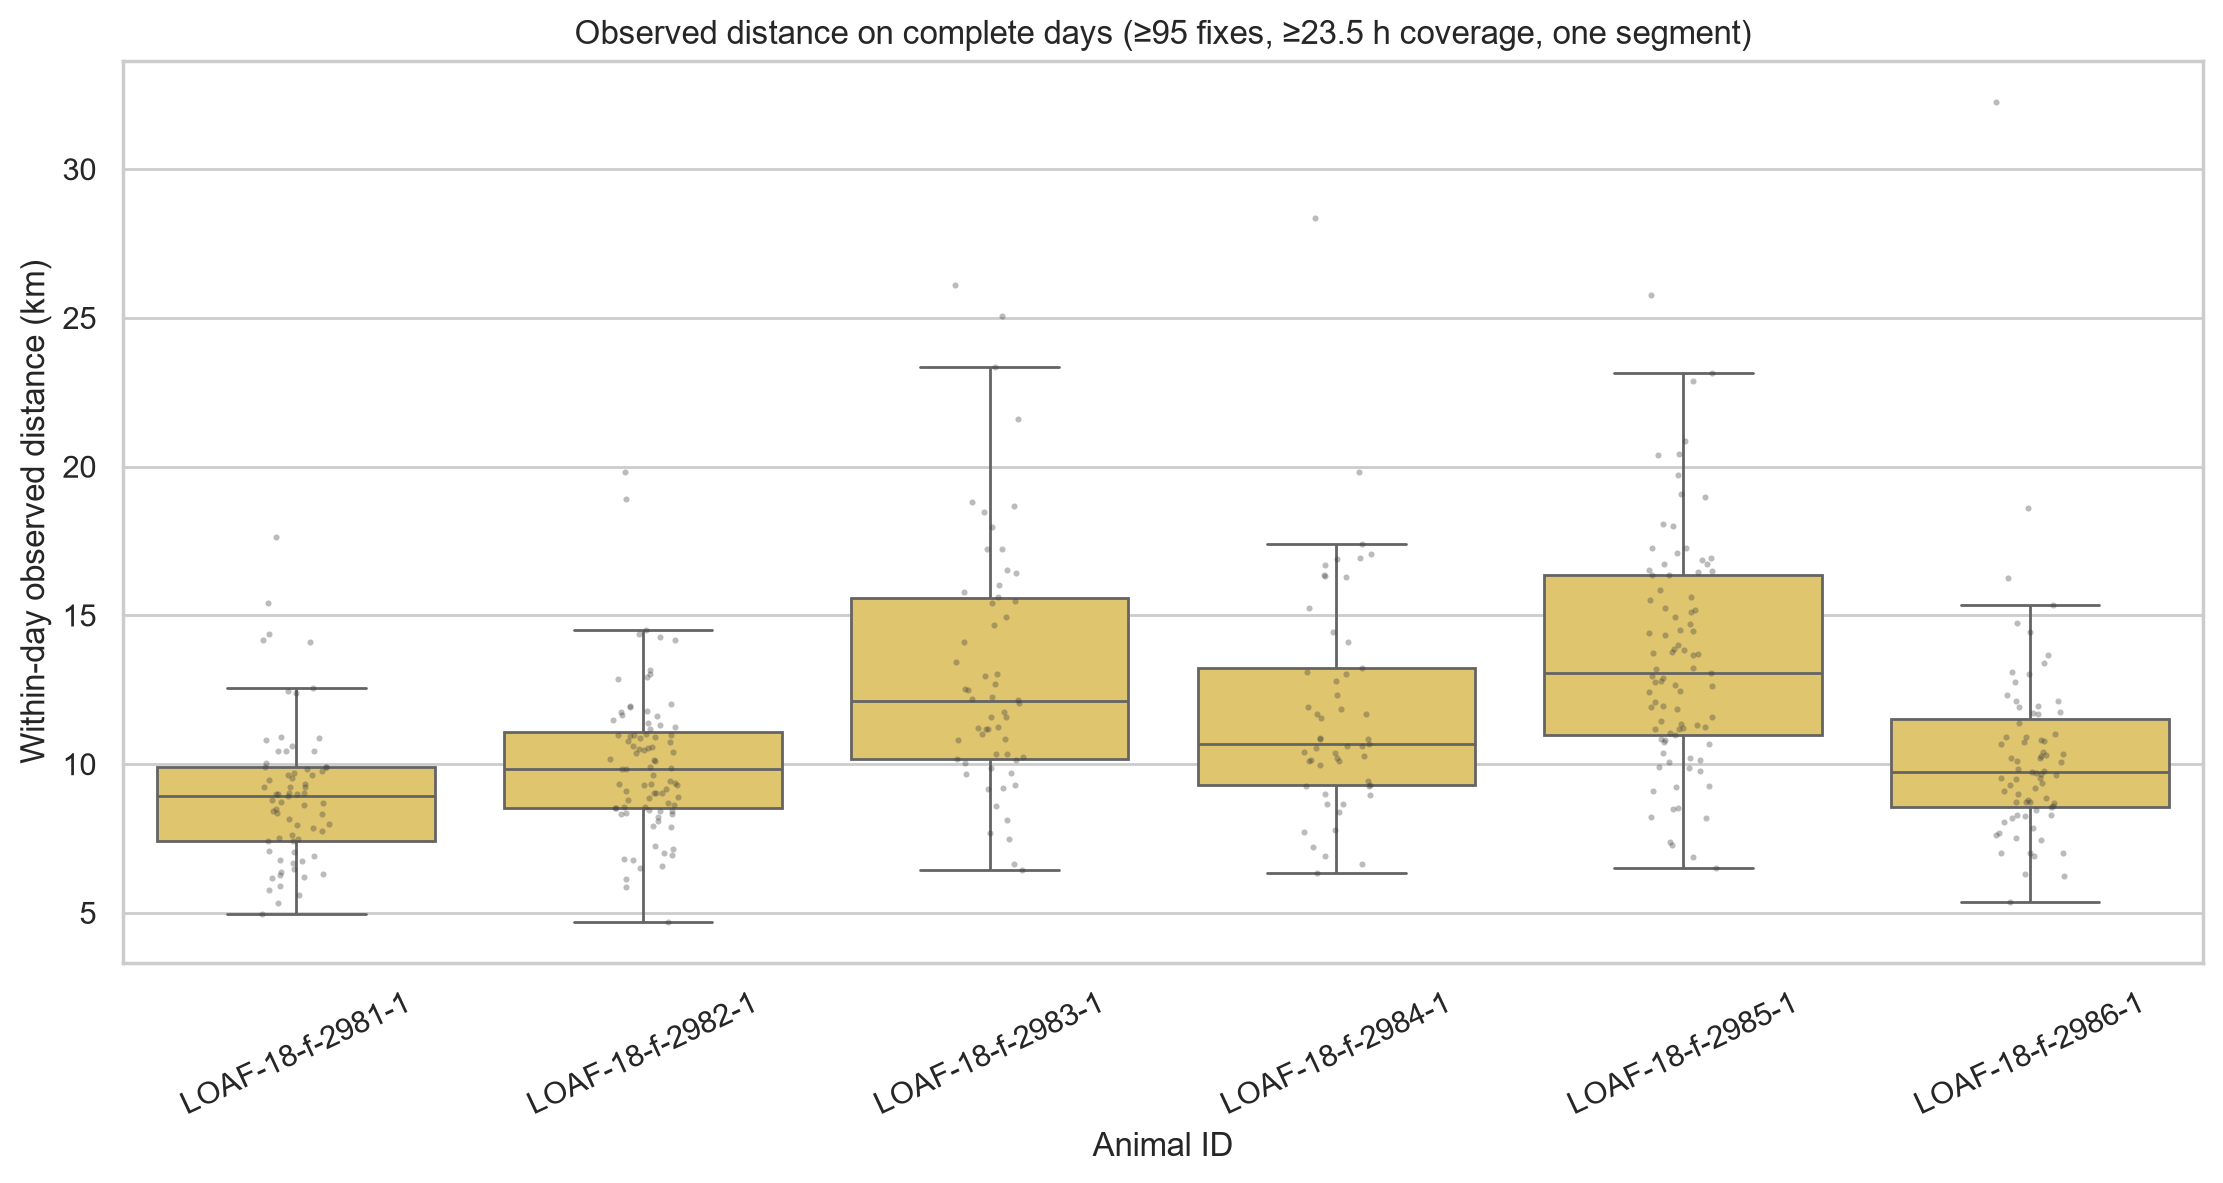

In [9]:
for figure_path in figure_paths:
    display(
        Image(
            filename=str(figure_path),
            width=950
        )
    )

In [10]:
assert len(cleaned) == EXPECTED_CLEAN_ROWS

assert len(removed) == EXPECTED_REMOVED_SPIKES

assert (
    cleaned["SegmentID"].nunique()
    == EXPECTED_SEGMENTS
)

assert cleaned.loc[
    cleaned["SegmentStart"],
    [
        "StepTime_s",
        "StepDistance_m",
        "Speed_mps",
    ],
].isna().all().all()


print("WEEK 2 NOTEBOOK CHECKS PASSED")

WEEK 2 NOTEBOOK CHECKS PASSED
